# Portion 4 — Forecasting, generalisation & physics-aware learning (GPU optional)
**Question:** from the last 14 s of an HS-AFM movie, can a model forecast the surface state **+10 / +30 / +60 s** ahead —
on a concentration it has **never seen** (not even during self-supervised pretraining)?

**Inputs:** Portion 2 measurements (`targets_per_frame.csv`) and Portion 3 frozen embeddings (`portion3_outputs/embeddings/`).

| Forecast target | Definition (from Portion 2) | Valid where |
|---|---|---|
| `coverage` | footprint coverage θ | contrast OK |
| `log_peak` | log FFT lattice peak ratio (lattice sharpness) | all frames |
| `psi6` | FFT 6-fold order ψ6 | dense (θ ≥ 0.9) |
| `log_density` | log(1 + triangles µm⁻²) | sparse (θ ≤ 0.6) |

| Model | Uses images? | Trained? |
|---|---|---|
| Persistence / Linear extrapolation / Kinetic (pseudo-first-order fit of the history) | no | no |
| MLP on current descriptors, GRU on the descriptor history | no | yes |
| Frozen encoder **B0 / B2 / B3 / B4 / B5** + MLP head | yes | head only |
| **B4 + physics loss (proposed)**, B5 + physics loss (shuffled-time control) | yes | head only |

All learned models forecast the **change from the current state** (residual on persistence, logit space for bounded targets),
so a model can only beat persistence by learning real dynamics.

**Physics loss** (two explicit, falsifiable terms): (1) coverage must not decrease across horizons beyond noise ε;
(2) in the sparse regime predicted coverage must agree with predicted density × single-triangle footprint.
**Evaluation:** leave-one-concentration-out (primary), P1 low→high and P1r high→low (secondary); 3 seeds; paired exact sign-flip tests over folds.
Runtime: ~5–15 min on a GPU, ~30–60 min on CPU (everything is cached and resumable).

In [1]:
# ---- 0. Mount Google Drive -------------------------------------------------
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab - using local paths.')

Mounted at /content/drive


In [2]:
# ---- 1. Imports & device ----------------------------------------------------------
import os, json, time, math, warnings, itertools, platform
from datetime import datetime
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.optimize import curve_fit
from scipy.stats import spearmanr, t as t_dist
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display
warnings.filterwarnings('ignore')
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device', DEVICE, '| numpy', np.__version__, '| pandas', pd.__version__)

torch 2.11.0+cpu | device cpu | numpy 2.1.3 | pandas 2.2.3


In [3]:
# ---- 2. Configuration --------------------------------------------------------------------------------
DATA_DIR = '/content/drive/MyDrive/Koushik-experiment/'
DATA_DIR = os.environ.get('HSAFM_DATA_DIR', DATA_DIR)          # (local-testing override; ignore in Colab)
P1_DIR, P2_DIR, P3_DIR = [os.path.join(DATA_DIR, f'portion{i}_outputs') for i in (1, 2, 3)]
OUT_DIR = os.path.join(DATA_DIR, 'portion4_outputs'); FIG = os.path.join(OUT_DIR, 'figures'); PRED = os.path.join(OUT_DIR, 'predictions')
for d in [OUT_DIR, FIG, PRED]:
    os.makedirs(d, exist_ok=True)
p3cfg = json.load(open(os.path.join(P3_DIR, 'run_config_portion3.json')))
QUICK_P3 = bool(p3cfg.get('QUICK', False))
TARGET_DT = float(p3cfg['config'].get('TARGET_DT', 2.0)); WINDOW = int(p3cfg['config'].get('T_FRAMES', 8))

HORIZONS = (10.0, 30.0, 60.0)                 # seconds ahead
TARGETS = ['coverage', 'log_peak', 'psi6', 'log_density']
PRIMARY = ('coverage', 30.0)                  # primary endpoint: coverage MAE at +30 s
SEEDS = (0, 1, 2)
EPOCHS, BATCH, LR, WD, HIDDEN, DROPOUT = 60, 512, 1e-3, 1e-4, 256, 0.1
EPS_MONO, TOL_CONS = 0.02, 0.05               # physics tolerances (coverage units)
LAMBDA_MONO, LAMBDA_CONS = 1.0, 1.0
SPARSE_MAX_COV = 0.60
PROPOSED = 'B4+phys'
FORCE = False
P4_VERSION = 'v1.3'      # bump after editing the models -> cached predictions are recomputed
if os.environ.get('HSAFM_QUICK', '0') == '1' or QUICK_P3:
    EPOCHS, SEEDS = 15, (0, 1)
PRED_KEY = json.dumps(dict(v=P4_VERSION, H=HORIZONS, S=SEEDS, E=EPOCHS, B=BATCH, LR=LR, WD=WD, HID=HIDDEN, DO=DROPOUT, eps=EPS_MONO,
                           tol=TOL_CONS, lm=LAMBDA_MONO, lc=LAMBDA_CONS, W=WINDOW, dt=TARGET_DT), sort_keys=True)
print(f'window {WINDOW} frames x {TARGET_DT:.0f} s | horizons {HORIZONS} s | seeds {SEEDS} | epochs {EPOCHS} | Portion-3 QUICK={QUICK_P3}')

window 8 frames x 2 s | horizons (10.0, 30.0, 60.0) s | seeds (0, 1, 2) | epochs 60 | Portion-3 QUICK=False


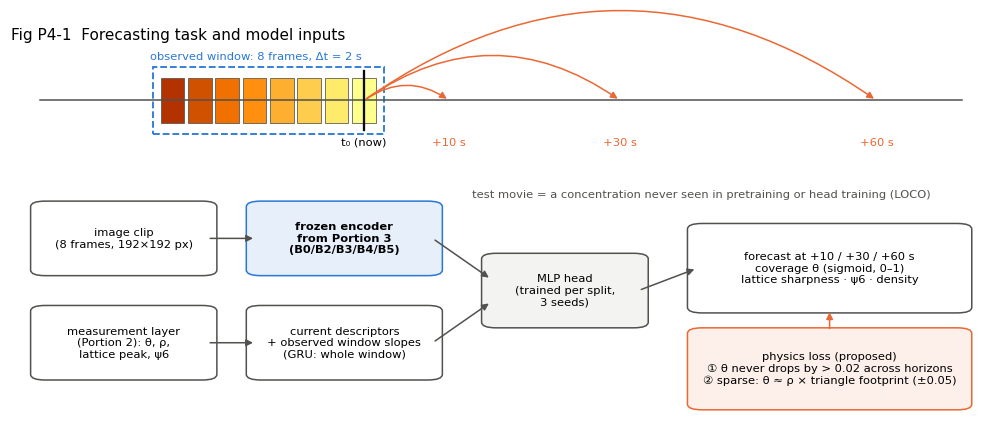

In [4]:
# ---- 3. Style + task diagram (Fig P4-1) ---------------------------------------------------------------
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 9, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5,
                     'lines.linewidth': 1.6, 'legend.frameon': False})
_ALL = ['2nM', '4nM', '6nM', '8nM', '10nM', '12nM']
CCOL = {c: plt.get_cmap('Blues')(0.35 + 0.6 * i / 5) for i, c in enumerate(_ALL)}
# baselines: greys (+ line styles); image models: validated categorical order; proposed = blue
MCOL = {'persistence': '#b5b5b5', 'linear': '#8f8f8f', 'kinetic': '#5c5c5c', 'MLP-desc': '#3a3a3a', 'GRU-desc': '#1f1f1f',
        'B0': '#cfcfcf', 'B2': '#1baf7a', 'B3': '#eb6834', 'B4': '#6250d6', 'B5+phys': '#eda100', 'B4+phys': '#2a78d6', 'B5': '#e87ba4'}
MLS = {'persistence': ':', 'linear': '-.', 'kinetic': '--', 'MLP-desc': (0, (3, 1, 1, 1)), 'GRU-desc': (0, (5, 1))}

def box(ax, x, y, w, h, text, fc='#ffffff', ec='#52514e', fs=7.5, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.01,rounding_size=0.015', fc=fc, ec=ec, lw=1.0))
    ax.text(x + w / 2, y + h / 2, text, ha='center', va='center', fontsize=fs, weight='bold' if bold else 'normal')

def arrow(ax, x0, y0, x1, y1, color='#52514e'):
    ax.annotate('', xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle='-|>', color=color, lw=1.0))

fig, ax = plt.subplots(figsize=(11.5, 4.4)); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
# timeline
x0_, x1_ = 0.03, 0.97; t0x = 0.36; sec = (x1_ - t0x) / 70.0
ax.plot([x0_, x1_], [0.86, 0.86], color='#52514e', lw=1)
for k in range(WINDOW):
    xx = t0x - (WINDOW - 1 - k) * TARGET_DT * sec * 1.6
    ax.add_patch(plt.Rectangle((xx - 0.012, 0.80), 0.024, 0.12, fc=plt.get_cmap('afmhot')(0.35 + 0.06 * k), ec='#52514e', lw=0.5))
ax.add_patch(plt.Rectangle((t0x - (WINDOW - 1) * TARGET_DT * sec * 1.6 - 0.02, 0.77), (WINDOW - 1) * TARGET_DT * sec * 1.6 + 0.04, 0.18,
                           fc='none', ec='#2a78d6', lw=1.2, ls='--'))
ax.text(t0x - 0.11, 0.97, f'observed window: {WINDOW} frames, Δt = {TARGET_DT:.0f} s', fontsize=7.5, color='#2a78d6', ha='center')
ax.plot([t0x, t0x], [0.78, 0.94], color='#0b0b0b', lw=1.5); ax.text(t0x, 0.74, 't₀ (now)', ha='center', fontsize=7.5)
for h in HORIZONS:
    xx = t0x + h * sec
    ax.annotate('', xy=(xx, 0.86), xytext=(t0x, 0.86), arrowprops=dict(arrowstyle='-|>', color='#eb6834', lw=1.0, connectionstyle='arc3,rad=-0.35'))
    ax.text(xx, 0.74, f'+{h:.0f} s', ha='center', fontsize=7.5, color='#eb6834')
# pipeline
box(ax, 0.03, 0.40, 0.17, 0.18, 'image clip\n(8 frames, 192×192 px)')
box(ax, 0.25, 0.40, 0.18, 0.18, 'frozen encoder\nfrom Portion 3\n(B0/B2/B3/B4/B5)', fc='#e6effa', ec='#2a78d6', bold=True)
box(ax, 0.03, 0.12, 0.17, 0.18, 'measurement layer\n(Portion 2): θ, ρ,\nlattice peak, ψ6')
box(ax, 0.25, 0.12, 0.18, 0.18, 'current descriptors\n+ observed window slopes\n(GRU: whole window)')
box(ax, 0.49, 0.26, 0.15, 0.18, 'MLP head\n(trained per split,\n3 seeds)', fc='#f3f3f1')
box(ax, 0.70, 0.30, 0.27, 0.22, 'forecast at +10 / +30 / +60 s\ncoverage θ (sigmoid, 0–1)\nlattice sharpness · ψ6 · density', fc='#ffffff')
box(ax, 0.70, 0.04, 0.27, 0.20, f'physics loss (proposed)\n① θ never drops by > {EPS_MONO} across horizons\n② sparse: θ ≈ ρ × triangle footprint (±{TOL_CONS})',
    fc='#fdf0ea', ec='#eb6834')
arrow(ax, 0.20, 0.49, 0.25, 0.49); arrow(ax, 0.20, 0.21, 0.25, 0.21)
arrow(ax, 0.43, 0.49, 0.49, 0.38); arrow(ax, 0.43, 0.21, 0.49, 0.32); arrow(ax, 0.64, 0.35, 0.70, 0.41)
arrow(ax, 0.835, 0.24, 0.835, 0.30, color='#eb6834')
ax.text(0.47, 0.60, 'test movie = a concentration never seen in pretraining or head training (LOCO)', fontsize=7.5, color='#52514e')
ax.set_title('Fig P4-1  Forecasting task and model inputs', fontsize=10, loc='left')
fig.savefig(os.path.join(FIG, 'figP4_1_task_diagram.png'), bbox_inches='tight'); plt.show()

In [5]:
# ---- 4. Assemble anchors, histories and future targets ------------------------------------------------------
idx = pd.read_csv(os.path.join(P3_DIR, 'dataset_index.csv'))                 # row order of every embedding file
tg = pd.read_csv(os.path.join(P2_DIR, 'targets_per_frame.csv')).set_index('frame_id')
splits = json.load(open(os.path.join(P1_DIR, 'splits.json')))['splits']
conc_order = lambda c: float(str(c).replace('nM', ''))
A = idx.join(tg[['coverage', 'contrast_ok', 'fft_peak_ratio', 'fft_psi6', 'lattice_valid', 'density_um2', 'count_valid', 'regime']], on='frame_id')
CONCS = sorted(A.conc.unique(), key=conc_order)
N = len(A)
Y = np.full((N, 4), np.nan)
Y[:, 0] = np.where(A.contrast_ok.astype(bool), A.coverage, np.nan)
Y[:, 1] = np.where(A.fft_peak_ratio > 0, np.log(A.fft_peak_ratio.clip(lower=1e-6)), np.nan)
Y[:, 2] = np.where(A.lattice_valid.astype(bool), A.fft_psi6, np.nan)
Y[:, 3] = np.where(A.count_valid.astype(bool) & A.density_um2.notna(), np.log1p(A.density_um2.clip(lower=0)), np.nan)
# start-up / unstable-tip frames flagged in Portion 1 (warn_streaks) give artefactual measurements -> treated as unmeasured
fr1 = pd.read_csv(os.path.join(P1_DIR, 'frames_all.csv'))[['frame_id', 'warn_streaks']].set_index('frame_id')
STREAK = A.frame_id.map(fr1.warn_streaks).fillna(False).astype(bool).values
Y[STREAK, :] = np.nan
MY = np.isfinite(Y)
print(f'{int(STREAK.sum())} streak-flagged frames treated as unmeasured:', dict(pd.Series(A.conc.values[STREAK]).value_counts().reindex(CONCS).fillna(0).astype(int)))

# history (causal, same session, stride ~TARGET_DT) - identical rule to Portion 3 clips
A['pos'] = A.groupby('session').cumcount()
dts = A.groupby('session').t_rel_s.apply(lambda s: float(np.median(np.diff(s.values))) if len(s) > 1 else TARGET_DT)
A['stride'] = A.session.map(lambda s: max(1, int(round(TARGET_DT / max(dts[s], 1e-3)))))
first = A.groupby('session').cumcount() == 0
sess_start = A.index.values - A.pos.values                                   # global row of each session's first frame
HIST = np.zeros((N, WINDOW), int)
for k in range(WINDOW):
    HIST[:, WINDOW - 1 - k] = sess_start + np.clip(A.pos.values - k * A.stride.values, 0, None)
T_ABS = A.t_rel_s.values

# future targets at t0 + h (same movie; nearest frame within tolerance)
YF = np.full((N, len(HORIZONS), 4), np.nan)
for c in CONCS:
    rows = np.where(A.conc.values == c)[0]; tt = T_ABS[rows]
    for hi, h in enumerate(HORIZONS):
        j = np.searchsorted(tt, tt + h).clip(0, len(tt) - 1)
        jm = (j - 1).clip(0)
        jj = np.where(np.abs(tt[jm] - (tt + h)) < np.abs(tt[j] - (tt + h)), jm, j)
        ok = np.abs(tt[jj] - (tt + h)) <= max(3.0, 0.15 * h)
        YF[rows[ok], hi] = Y[rows[jj[ok]]]
MF = np.isfinite(YF)
anchor_ok = MY[:, 0] & MF[:, :, 0].any(1)                                     # current coverage known and >=1 future target
print(f'{N} frames | {anchor_ok.sum()} anchors with a valid future | per concentration:',
      dict(pd.Series(A.conc.values[anchor_ok]).value_counts().reindex(CONCS)))

# descriptor history features (NaN -> 0 + validity flags)
def desc_features(rows_hist):
    yh = Y[rows_hist]; mh = MY[rows_hist].astype(float)
    dt = (T_ABS[rows_hist] - T_ABS[rows_hist[:, -1:]]) / 60.0
    return np.concatenate([np.nan_to_num(yh), mh, dt[..., None]], axis=-1).astype(np.float32)   # (n, W, 9)
DH = desc_features(HIST)                    # (N, W, 9)

def window_slopes(rows_hist):
    """observed rate of change of every target over the window (per minute, least squares) + validity."""
    tt = (T_ABS[rows_hist] - T_ABS[rows_hist[:, -1:]]) / 60.0
    out, val = np.zeros((len(rows_hist), 4), np.float32), np.zeros((len(rows_hist), 4), np.float32)
    for k in range(4):
        y = Y[rows_hist][:, :, k]; m = np.isfinite(y); y0 = np.nan_to_num(y)
        S, St, Sy, Stt, Sty = m.sum(1), (m * tt).sum(1), (m * y0).sum(1), (m * tt ** 2).sum(1), (m * tt * y0).sum(1)
        den = S * Stt - St ** 2; ok = (S >= 3) & (den > 1e-12)
        out[ok, k] = ((S * Sty - St * Sy) / np.where(ok, den, 1))[ok]; val[ok, k] = 1
    return np.concatenate([out, val], 1)
# current descriptors = current values/flags + the rate of change observed in the window (lets the head see THIS movie's speed)
DN = np.concatenate([DH[:, -1, :], window_slopes(HIST)], 1)

87 streak-flagged frames treated as unmeasured: {'2nM': np.int64(4), '4nM': np.int64(17), '6nM': np.int64(0), '8nM': np.int64(33), '10nM': np.int64(33)}
4036 frames | 3926 anchors with a valid future | per concentration: {'2nM': np.int64(586), '4nM': np.int64(865), '6nM': np.int64(793), '8nM': np.int64(821), '10nM': np.int64(861)}


In [6]:
# ---- 5. Training-free baselines (computed once) -------------------------------------------------------------------
def pfo(t, th_inf, th0, k):
    return th_inf - (th_inf - th0) * np.exp(-k * t)

def baselines_all():
    f = os.path.join(PRED, 'baselines.npz')
    if os.path.exists(f) and not FORCE:
        d = np.load(f)
        if d['persistence'].shape == (N, len(HORIZONS), 4) and 'key' in d.files and str(d['key']) == PRED_KEY:
            return {k: d[k] for k in ('persistence', 'linear', 'kinetic')}
    t0_ = time.time()
    H = np.array(HORIZONS)
    # persistence = last valid value inside the window (else NaN -> filled with train mean later)
    pers = np.full((N, 4), np.nan)
    for k in range(WINDOW - 1, -1, -1):
        v = Y[HIST[:, k]]; fill = np.isnan(pers) & np.isfinite(v); pers[fill] = v[fill]
    P_pers = np.repeat(pers[:, None, :], len(H), 1)
    # linear least squares over the window
    tt = (T_ABS[HIST] - T_ABS[:, None]); P_lin = P_pers.copy()
    for kk in range(4):
        y = Y[HIST][:, :, kk]; m = np.isfinite(y); y0 = np.nan_to_num(y)
        S, St, Sy, Stt, Sty = m.sum(1), (m * tt).sum(1), (m * y0).sum(1), (m * tt ** 2).sum(1), (m * tt * y0).sum(1)
        den = S * Stt - St ** 2; ok = (S >= 3) & (den > 1e-9)
        b = np.where(ok, (S * Sty - St * Sy) / np.where(ok, den, 1), 0); a = np.where(ok, (Sy - b * St) / np.maximum(S, 1), np.nan)
        for hi, h in enumerate(H):
            P_lin[ok, hi, kk] = a[ok] + b[ok] * h
    # kinetic: pseudo-first-order fit (θ∞, k) of the movie's coverage history up to t0, projected forward FROM THE CURRENT
    # coverage: θ(t0+h) = θ∞ - (θ∞ - θ_now)·exp(-k h)   (other targets: persistence)
    P_kin = P_lin.copy(); P_kin[:, :, 1:] = P_pers[:, :, 1:]
    th_now = np.nanmedian(np.where(MY[HIST[:, -3:], 0], Y[HIST[:, -3:], 0], np.nan), axis=1)
    for c in CONCS:
        rows = np.where(A.conc.values == c)[0]; tt_c, yc = T_ABS[rows], Y[rows, 0]
        prev = None
        for r_i, r in enumerate(rows):
            hm = np.isfinite(yc[:r_i + 1])
            th, yh = tt_c[:r_i + 1][hm], yc[:r_i + 1][hm]
            if len(th) < 10 or th[-1] - th[0] < 30 or not np.isfinite(th_now[r]):
                continue
            if len(th) > 300:
                sel = np.unique(np.r_[np.linspace(0, len(th) - 1, 200).astype(int), np.arange(len(th) - 100, len(th))]); th, yh = th[sel], yh[sel]
            try:
                p0 = prev if prev is not None else [float(np.clip(yh.max(), 0.01, 0.99)), float(np.clip(yh[0], 0, 0.99)), 0.01]
                p, _ = curve_fit(pfo, th - th[0], yh, p0=p0, bounds=([0, 0, 1e-6], [1.0, 1.0, 2.0]), maxfev=2000)
                prev = list(p)
                P_kin[r, :, 0] = p[0] - (p[0] - th_now[r]) * np.exp(-p[2] * H)
            except Exception:
                pass
    for P in (P_lin, P_kin):
        P[:, :, 0] = np.clip(P[:, :, 0], 0, 1); P[:, :, 2] = np.clip(P[:, :, 2], 0, 1)
    np.savez_compressed(f, persistence=P_pers, linear=P_lin, kinetic=P_kin, key=np.array(PRED_KEY))
    print(f'baselines computed in {time.time()-t0_:.0f}s')
    return dict(persistence=P_pers, linear=P_lin, kinetic=P_kin)

BASE = baselines_all()

baselines computed in 23s


In [7]:
# ---- 6. Learned models: MLP / GRU on descriptors, MLP heads on frozen embeddings (+ physics loss) ----------------------
class Head(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, HIDDEN), nn.GELU(), nn.Dropout(DROPOUT), nn.Linear(HIDDEN, HIDDEN), nn.GELU(),
                                 nn.Linear(HIDDEN, d_out))
        nn.init.zeros_(self.net[-1].weight); nn.init.zeros_(self.net[-1].bias)    # start exactly at persistence
    def forward(self, x):
        return self.net(x)

class GRUHead(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()
        self.gru = nn.GRU(d_in, 64, batch_first=True); self.out = Head(64, d_out)
    def forward(self, x):
        _, h = self.gru(x); return self.out(h[-1])

def logit(p):
    p = p.clamp(0.01, 0.99); return torch.log(p) - torch.log1p(-p)

def decode(o, base, ys):
    """RESIDUAL forecast: raw outputs (B, H*4) are CHANGES relative to the current state `base` (B, 4).
    coverage & psi6 move in logit space (always inside 0-1); log_peak & log_density move in standardised units.
    With zero-initialised output layers every model starts exactly at persistence."""
    o = o.view(o.shape[0], len(HORIZONS), 4); b = base[:, None, :]
    return torch.cat([torch.sigmoid(logit(b[..., 0:1]) + o[..., 0:1]), b[..., 1:2] + o[..., 1:2] * ys[1],
                      torch.sigmoid(logit(b[..., 2:3]) + o[..., 2:3]), b[..., 3:4] + o[..., 3:4] * ys[3]], -1)

def physics_terms(P, now_cov, a_area):
    """P: (B,H,4) physical predictions. Returns (monotonic-coverage penalty, coverage-density consistency penalty)."""
    cov = P[..., 0]
    mono = F.relu(cov[:, :-1] - cov[:, 1:] - EPS_MONO).mean()
    mono = mono + F.relu(now_cov - cov[:, 0] - EPS_MONO).mean()
    rho = torch.expm1(P[..., 3]).clamp(min=0)
    sparse = (cov.detach() < SPARSE_MAX_COV).float()
    cons = (F.relu((cov - a_area * rho).abs() - TOL_CONS) * sparse).sum() / sparse.sum().clamp(min=1)
    return mono, cons

def train_model(kind, Xtr, Ytr, Mtr, Xte, now_tr, base_tr, base_te, seed, phys, a_area, ym, ys):
    torch.manual_seed(seed); np.random.seed(seed)
    d_out = len(HORIZONS) * 4
    net = (GRUHead(Xtr.shape[-1], d_out) if kind == 'gru' else Head(Xtr.shape[-1], d_out)).to(DEVICE)
    opt = torch.optim.AdamW(net.parameters(), lr=LR, weight_decay=WD)
    n = len(Xtr); perm = np.random.permutation(n); nv = max(1, int(0.1 * n)); va, tr = perm[:nv], perm[nv:]
    Xt = torch.as_tensor(Xtr, device=DEVICE); Yt = torch.as_tensor(np.nan_to_num(Ytr), device=DEVICE, dtype=torch.float32)
    Mt = torch.as_tensor(Mtr, device=DEVICE, dtype=torch.float32); Nt = torch.as_tensor(now_tr, device=DEVICE, dtype=torch.float32)
    yst = torch.as_tensor(ys, device=DEVICE, dtype=torch.float32)
    Bt = torch.as_tensor(base_tr, device=DEVICE, dtype=torch.float32)
    def loss_fn(ix):
        P = decode(net(Xt[ix]), Bt[ix], yst)
        mse = (((P - Yt[ix]) / yst) ** 2 * Mt[ix]).sum() / Mt[ix].sum().clamp(min=1)
        if phys:
            mono, cons = physics_terms(P, Nt[ix], a_area)
            return mse + LAMBDA_MONO * mono + LAMBDA_CONS * cons, mse
        return mse, mse
    best, best_state = np.inf, None
    tr_t, va_t = torch.as_tensor(tr, device=DEVICE), torch.as_tensor(va, device=DEVICE)
    for ep in range(EPOCHS):
        net.train()
        for b in torch.split(tr_t[torch.randperm(len(tr_t), device=DEVICE)], BATCH):
            loss, _ = loss_fn(b); opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        net.eval()
        with torch.no_grad():
            vl = float(loss_fn(va_t)[0])
        if vl < best:
            best, best_state = vl, {k: v.detach().clone() for k, v in net.state_dict().items()}
    net.load_state_dict(best_state); net.eval()
    with torch.no_grad():
        return decode(net(torch.as_tensor(Xte, device=DEVICE)), torch.as_tensor(base_te, device=DEVICE, dtype=torch.float32), yst).cpu().numpy()

def emb_path(split, variant):
    return os.path.join(P3_DIR, 'embeddings', split, f'{variant}.npz')

AVAILABLE_V = [v for v in ['B0', 'B2', 'B3', 'B4', 'B5'] if os.path.exists(emb_path(list(splits)[0], v))]
MODELS = ['persistence', 'linear', 'kinetic', 'MLP-desc', 'GRU-desc'] + AVAILABLE_V
if 'B4' in AVAILABLE_V: MODELS.append('B4+phys')
if 'B5' in AVAILABLE_V: MODELS.append('B5+phys')
LEARNED = [m for m in MODELS if m not in ('persistence', 'linear', 'kinetic')]
SPLIT_LIST = [s for s in splits if os.path.exists(os.path.join(P3_DIR, 'embeddings', s))]
print('models:', MODELS); print('splits:', SPLIT_LIST)

def run_split(split):
    f = os.path.join(PRED, f'{split}.npz')
    if os.path.exists(f) and not FORCE:
        d = np.load(f, allow_pickle=True)
        if 'key' in d.files and set(d['models']) == set(MODELS) and str(d['key']) == PRED_KEY:
            return dict(d)
        print(f'   {split}: cached predictions are from other settings -> recomputing')
    tr_c, te_c = splits[split]['train'], splits[split]['test']
    tr = anchor_ok & A.conc.isin(tr_c).values; te = anchor_ok & A.conc.isin(te_c).values
    # target scaling & physics constant from TRAINING movies only
    yt = YF[tr]; ym = np.array([np.nanmean(yt[..., k]) for k in range(4)], np.float32); ys = np.array([np.nanstd(yt[..., k]) + 1e-3 for k in range(4)], np.float32)
    sp = tr & MY[:, 3] & MY[:, 0]
    a_area = float(np.median(Y[sp, 0] / np.expm1(Y[sp, 3]).clip(min=1e-3))) if sp.sum() > 10 else 0.01
    out = {'te_rows': np.where(te)[0], 'models': np.array(MODELS), 'a_area': a_area, 'key': np.array(PRED_KEY)}
    for m in ('persistence', 'linear', 'kinetic'):
        P = BASE[m][te].copy()
        for k in range(4):
            P[..., k] = np.where(np.isnan(P[..., k]), ym[k], P[..., k])
        out[m] = P[None]                                                      # (1, n, H, 4)
    dmu, dsd = DN[tr].mean(0), DN[tr].std(0) + 1e-6
    hmu, hsd = DH[tr].reshape(-1, DH.shape[-1]).mean(0), DH[tr].reshape(-1, DH.shape[-1]).std(0) + 1e-6
    now_cov = np.nan_to_num(Y[:, 0], nan=-1.0).astype(np.float32)          # -1 = unknown -> physics term inactive
    Ytr, Mtr = YF[tr].astype(np.float32), MF[tr]
    base = BASE['persistence'][:, 0, :].copy()                               # current state (last valid value in the window)
    for k in range(4):
        base[:, k] = np.where(np.isnan(base[:, k]), ym[k], base[:, k])
    base = base.astype(np.float32)
    Zs = {}
    for v in AVAILABLE_V:
        dz = np.load(emb_path(split, v), allow_pickle=True)
        assert set(te_c).isdisjoint(set(dz['train_concs'])), f'LEAKAGE: {v} encoder for {split} was pretrained on a test concentration'
        assert [str(x) for x in dz['frame_id']] == [str(x) for x in A.frame_id], 'embedding row order differs from dataset_index.csv'
        Z = dz['Z']; zmu, zsd = Z[tr].mean(0), Z[tr].std(0) + 1e-6; Zs[v] = ((Z - zmu) / zsd).astype(np.float32)
    for m in LEARNED:
        preds = []
        for sd in SEEDS:
            if m == 'MLP-desc':
                X = ((DN - dmu) / dsd).astype(np.float32); kind, phys = 'mlp', False
            elif m == 'GRU-desc':
                X = ((DH - hmu) / hsd).astype(np.float32); kind, phys = 'gru', False
            else:
                v = m.replace('+phys', ''); phys = m.endswith('+phys'); kind = 'mlp'
                X = np.concatenate([Zs[v], ((DN - dmu) / dsd).astype(np.float32)], 1)
            preds.append(train_model(kind, X[tr], Ytr, Mtr, X[te], now_cov[tr], base[tr], base[te], sd, phys, a_area, ym, ys))
        out[m] = np.stack(preds)                                              # (seeds, n, H, 4)
    np.savez_compressed(f, **out)
    return out

RES = {}
t0 = time.time()
for s in SPLIT_LIST:
    t1 = time.time(); RES[s] = run_split(s)
    print(f'{s:16s} test={splits[s]["test"]}  n_test={len(RES[s]["te_rows"])}  ({time.time()-t1:.0f}s)')
print(f'all splits done in {time.time()-t0:.0f}s')

models: ['persistence', 'linear', 'kinetic', 'MLP-desc', 'GRU-desc', 'B0', 'B2', 'B3', 'B4', 'B5', 'B4+phys', 'B5+phys']
splits: ['LOCO_2nM', 'LOCO_4nM', 'LOCO_6nM', 'LOCO_8nM', 'LOCO_10nM', 'P1_low_to_high', 'P1r_high_to_low']
LOCO_2nM         test=['2nM']  n_test=586  (237s)
LOCO_4nM         test=['4nM']  n_test=865  (212s)
LOCO_6nM         test=['6nM']  n_test=793  (215s)
LOCO_8nM         test=['8nM']  n_test=821  (210s)
LOCO_10nM        test=['10nM']  n_test=861  (209s)
P1_low_to_high   test=['8nM', '10nM']  n_test=1682  (157s)
P1r_high_to_low  test=['2nM', '4nM', '6nM']  n_test=2244  (118s)
all splits done in 1357s


In [8]:
# ---- 7. Metrics -----------------------------------------------------------------------------------------------------------
def r2(y, p):
    ss = np.sum((y - y.mean()) ** 2); return 1 - np.sum((y - p) ** 2) / ss if ss > 0 else np.nan

def violation_rates(P, rows, a_area):
    cov = P[..., 0]; now = Y[rows, 0]
    mono = (np.any(cov[:, :-1] - cov[:, 1:] > EPS_MONO, axis=1) | (np.isfinite(now) & (now - cov[:, 0] > EPS_MONO))).mean()
    rho = np.expm1(P[..., 3]).clip(min=0); sp = cov < SPARSE_MAX_COV
    cons = (np.abs(cov - a_area * rho)[sp] > TOL_CONS).mean() if sp.any() else np.nan
    return float(mono), float(cons)

rows_ = []
for s, R in RES.items():
    te_rows = R['te_rows']; Yt, Mt = YF[te_rows], MF[te_rows]
    for m in MODELS:
        P = R[m].mean(0)                                                     # seed ensemble
        vm, vc = violation_rates(P, te_rows, float(R['a_area']))
        for hi, h in enumerate(HORIZONS):
            for k, tn in enumerate(TARGETS):
                ok = Mt[:, hi, k]
                if ok.sum() < 3: continue
                y, p = Yt[ok, hi, k], P[ok, hi, k]
                seed_mae = [float(np.mean(np.abs(R[m][j][ok, hi, k] - y))) for j in range(R[m].shape[0])]
                rows_.append(dict(split=s, test='+'.join(splits[s]['test']), model=m, target=tn, horizon=h, n=int(ok.sum()),
                                  MAE=float(np.mean(np.abs(p - y))), RMSE=float(np.sqrt(np.mean((p - y) ** 2))), R2=r2(y, p),
                                  spearman=float(spearmanr(y, p).statistic) if np.std(p) > 0 and np.std(y) > 0 else np.nan,
                                  MAE_seed_sd=float(np.std(seed_mae)), viol_mono=vm, viol_cons=vc))
MET = pd.DataFrame(rows_)
MET.to_csv(os.path.join(OUT_DIR, 'metrics_all.csv'), index=False)
loco = [s for s in SPLIT_LIST if s.startswith('LOCO_')]
L = MET[MET.split.isin(loco)]
prim = L[(L.target == PRIMARY[0]) & (L.horizon == PRIMARY[1])]
tab = prim.pivot(index='model', columns='test', values='MAE').reindex(MODELS)
tab = tab[[c for c in CONCS if c in tab.columns]]
tab['mean'] = tab.mean(1); tab['folds won vs persistence'] = (tab[[c for c in CONCS if c in tab.columns]].lt(tab.loc['persistence'], axis=1)).sum(1)
print(f'PRIMARY ENDPOINT: {PRIMARY[0]} MAE at +{PRIMARY[1]:.0f} s, per held-out concentration (LOCO)')
display(tab.round(4))
summary = L.groupby(['target', 'horizon', 'model']).MAE.mean().unstack('model')[MODELS]
display(summary.round(4))

PRIMARY ENDPOINT: coverage MAE at +30 s, per held-out concentration (LOCO)


test,2nM,4nM,6nM,8nM,10nM,mean,folds won vs persistence
model,,,,,,,
persistence,0.0139,0.0256,0.0195,0.0174,0.0271,0.0207,0
linear,0.0303,0.0323,0.0121,0.0132,0.0164,0.0209,3
kinetic,0.0260,0.0258,0.0124,0.0148,0.0191,0.0196,3
MLP-desc,0.0241,0.0401,0.0131,0.0137,0.0224,0.0227,3
GRU-desc,0.1020,0.0688,0.0104,0.0118,0.0264,0.0439,3
B0,0.1528,0.0304,0.0091,0.0179,0.0181,0.0457,2
B2,0.0600,0.0613,0.0117,0.0270,0.0180,0.0356,2
B3,0.0787,0.0409,0.0137,0.0267,0.0230,0.0366,2
B4,0.1319,0.0658,0.0108,0.0269,0.0237,0.0518,2


model                persistence  linear  kinetic  MLP-desc  GRU-desc      B0      B2      B3      B4      B5  B4+phys  B5+phys
target      horizon                                                                                                            
coverage    10.0          0.0101  0.0109   0.0114    0.0135    0.0163  0.0309  0.0226  0.0256  0.0266  0.0256   0.0250   0.0246
            30.0          0.0207  0.0209   0.0196    0.0227    0.0439  0.0457  0.0356  0.0366  0.0518  0.0509   0.0485   0.0460
            60.0          0.0340  0.0326   0.0290    0.0381    0.1293  0.0491  0.0553  0.0547  0.0918  0.0969   0.0932   0.0952
log_density 10.0          0.1562  0.1540   0.1562    0.1593    0.1911  0.1697  0.1738  0.1759  0.2036  0.1849   0.2059   0.1947
            30.0          0.2637  0.3344   0.2637    0.2473    0.3809  0.3031  0.1923  0.2745  0.2086  0.1706   0.3285   0.3287
            60.0          0.4628  0.8519   0.4628    0.4998    0.6424  0.5715  0.4433  0.7032  0.4353  0.4252   0.6171   0.6525
log_peak    10.0          0.2930  0.3937   0.2930    0.3186    0.2914  0.3772  0.3890  0.3151  0.3176  0.3374   0.3037   0.3329
            30.0          0.3497  0.7920   0.3497    0.3631    0.3368  0.4118  0.4246  0.3387  0.3495  0.3646   0.3496   0.3626
            60.0          0.3717  1.3572   0.3717    0.3743    0.3804  0.3836  0.4003  0.3553  0.3478  0.3322   0.3584   0.3341
psi6        10.0          0.0854  0.1104   0.0854    0.1033    0.0987  0.1249  0.1350  0.0994  0.0972  0.1083   0.0976   0.1089
            30.0          0.1049  0.1916   0.1049    0.1173    0.1120  0.1426  0.1300  0.1165  0.1171  0.1255   0.1169   0.1255
            60.0          0.1163  0.2647   0.1163    0.1391    0.1375  0.1377  0.1291  0.1281  0.1233  0.1352   0.1262   0.1352

In [9]:
# ---- 8. Paired statistics over LOCO folds (exact sign-flip test) --------------------------------------------------------
def signflip_p(d):
    d = np.asarray(d, float); d = d[np.isfinite(d)]; n = len(d)
    if n == 0: return np.nan
    obs = abs(d.mean()); signs = np.array(list(itertools.product([-1, 1], repeat=n)))
    return float(np.mean(np.abs((signs * d).mean(1)) >= obs - 1e-12))

def bh(p):
    p = np.asarray(p, float); n = np.sum(np.isfinite(p)); o = np.argsort(np.where(np.isfinite(p), p, np.inf))
    q = np.full_like(p, np.nan); prev = 1.0
    for rank, i in reversed(list(enumerate(o[:n], start=1))):
        prev = min(prev, p[i] * n / rank); q[i] = prev
    return q

stats = []
if PROPOSED in MODELS and len(loco) >= 2:
    base_mae = tab.loc[PROPOSED, [c for c in CONCS if c in tab.columns]]
    for m in MODELS:
        if m == PROPOSED: continue
        comp = tab.loc[m, base_mae.index]; d = (comp - base_mae).values                  # >0: proposed better
        sd = np.std(d, ddof=1) if len(d) > 1 else np.nan
        ci = t_dist.ppf(0.975, len(d) - 1) * sd / np.sqrt(len(d)) if len(d) > 1 else np.nan
        stats.append(dict(comparator=m, mean_MAE_comparator=comp.mean(), mean_MAE_proposed=base_mae.mean(),
                          mean_improvement=d.mean(), CI95_low=d.mean() - ci, CI95_high=d.mean() + ci,
                          cohens_dz=d.mean() / sd if sd and sd > 0 else np.nan, folds_won=int((d > 0).sum()), n_folds=len(d),
                          p_signflip=signflip_p(d)))
STATS = pd.DataFrame(stats)
if len(STATS):
    STATS['q_BH'] = bh(STATS.p_signflip.values)
    print(f'Proposed ({PROPOSED}) vs each comparator - {PRIMARY[0]} MAE @ +{PRIMARY[1]:.0f} s, paired over {len(loco)} LOCO folds')
    print(f'(with n folds the smallest possible two-sided sign-flip p is {2/2**len(loco):.3f})')
    display(STATS.round(4))
    STATS.to_csv(os.path.join(OUT_DIR, 'paired_stats_primary.csv'), index=False)

Proposed (B4+phys) vs each comparator - coverage MAE @ +30 s, paired over 5 LOCO folds
(with n folds the smallest possible two-sided sign-flip p is 0.062)


,comparator,mean_MAE_comparator,mean_MAE_proposed,mean_improvement,CI95_low,CI95_high,cohens_dz,folds_won,n_folds,p_signflip,q_BH
0,persistence,0.0207,0.0485,-0.0278,-0.0827,0.0271,-0.6279,2,5,0.3125,0.5156
1,linear,0.0209,0.0485,-0.0276,-0.0691,0.0139,-0.8266,1,5,0.1250,0.4583
2,kinetic,0.0196,0.0485,-0.0288,-0.0739,0.0162,-0.7945,1,5,0.1250,0.4583
3,MLP-desc,0.0227,0.0485,-0.0258,-0.0716,0.0200,-0.7000,1,5,0.1250,0.4583
4,GRU-desc,0.0439,0.0485,-0.0046,-0.0136,0.0044,-0.6366,2,5,0.3750,0.5156
5,B0,0.0457,0.0485,-0.0028,-0.0375,0.0318,-0.1009,1,5,0.6875,0.8403
6,B2,0.0356,0.0485,-0.0129,-0.0408,0.0150,-0.5739,2,5,0.2500,0.5156
7,B3,0.0366,0.0485,-0.0118,-0.0333,0.0096,-0.6867,2,5,0.3750,0.5156
8,B4,0.0518,0.0485,0.0033,-0.0079,0.0145,0.3672,2,5,0.8750,0.8750
9,B5,0.0509,0.0485,0.0024,-0.0110,0.0158,0.2218,2,5,0.8750,0.8750


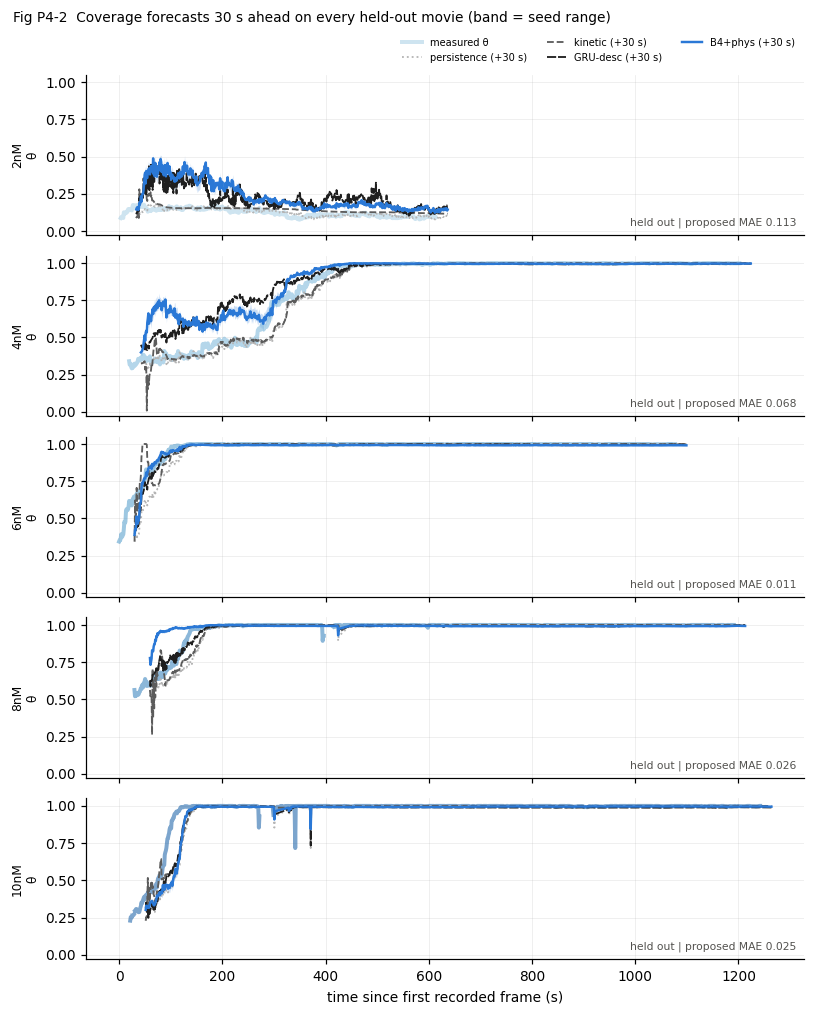

In [10]:
# ---- 9. Fig P4-2: observed vs forecast coverage for EVERY held-out movie -----------------------------------------------------
hi30 = HORIZONS.index(30.0) if 30.0 in HORIZONS else 1
show_models = [m for m in ['persistence', 'kinetic', 'GRU-desc', PROPOSED] if m in MODELS]
n_ = len(loco)
fig, axes = plt.subplots(n_, 1, figsize=(7.4, 1.75 * n_ + 0.6), sharex=True, squeeze=False)
for ax, s in zip(axes[:, 0], loco):
    R = RES[s]; te_rows = R['te_rows']; c = splits[s]['test'][0]
    tt = T_ABS[te_rows] + HORIZONS[hi30]
    rr = np.where(A.conc.values == c)[0]
    ax.plot(T_ABS[rr], Y[rr, 0], color=CCOL.get(c, 'k'), lw=2.6, alpha=0.55, label='measured θ')
    for m in show_models:
        P = R[m][:, :, hi30, 0]; o = np.argsort(tt)
        if m == PROPOSED and P.shape[0] > 1:
            ax.fill_between(tt[o], P.min(0)[o], P.max(0)[o], color=MCOL[m], alpha=0.25, lw=0)
        ax.plot(tt[o], P.mean(0)[o], color=MCOL[m], ls=MLS.get(m, '-'), lw=1.2 if m != PROPOSED else 1.6, label=f'{m} (+{HORIZONS[hi30]:.0f} s)')
    ax.set_ylim(-0.03, 1.05); ax.set_ylabel(f'{c}\nθ', fontsize=8)
    mm_ = MET[(MET.split == s) & (MET.model == PROPOSED) & (MET.target == 'coverage') & (MET.horizon == HORIZONS[hi30])].MAE
    ax.text(0.99, 0.06, 'held out' + (f' | proposed MAE {mm_.iloc[0]:.3f}' if len(mm_) else ''), transform=ax.transAxes, ha='right',
            fontsize=7, color='#52514e')
axes[0, 0].legend(fontsize=6.5, ncol=3, loc='lower right', bbox_to_anchor=(1.0, 1.02))
axes[-1, 0].set_xlabel('time since first recorded frame (s)')
fig.suptitle(f'Fig P4-2  Coverage forecasts {HORIZONS[hi30]:.0f} s ahead on every held-out movie (band = seed range)', fontsize=9, x=0.01, ha='left')
fig.tight_layout(); fig.savefig(os.path.join(FIG, 'figP4_2_forecast_curves_heldout.png'), bbox_inches='tight'); plt.show()

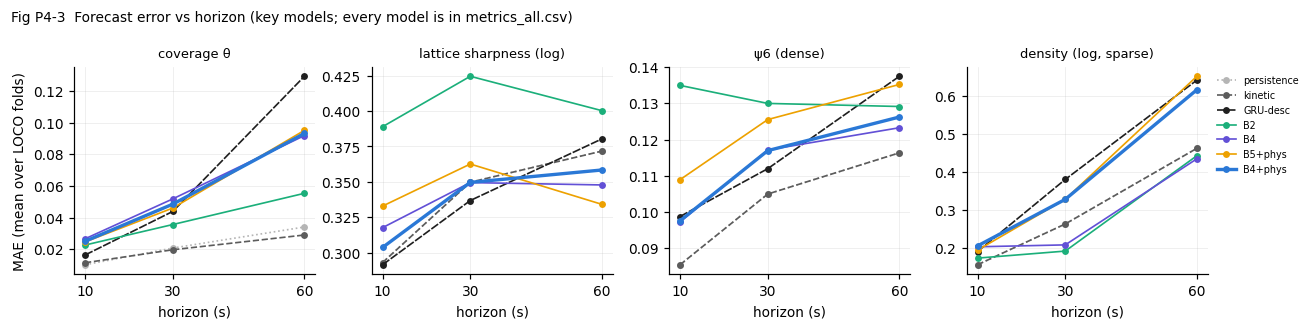

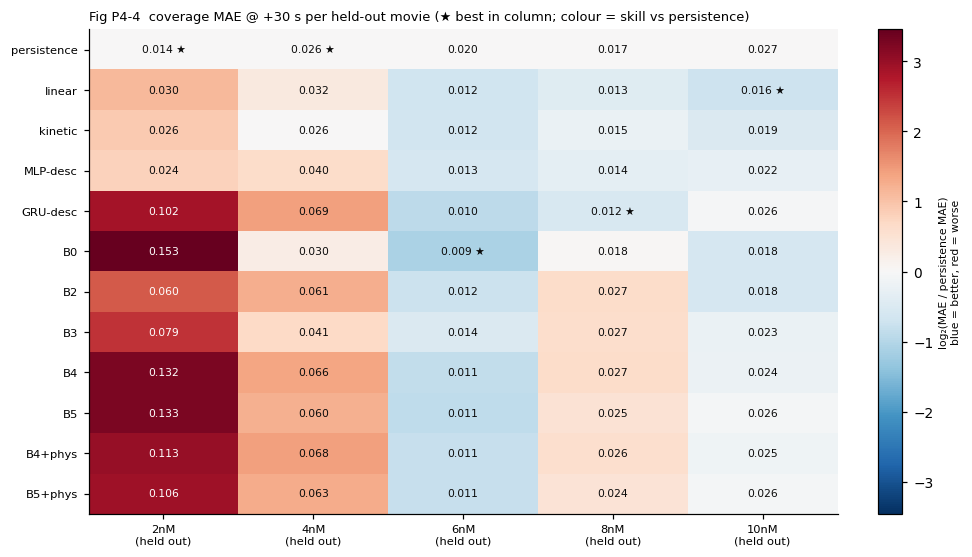

In [11]:
# ---- 10. Fig P4-3: error vs horizon | Fig P4-4: model x held-out concentration heatmap --------------------------------------
TNAME = {'coverage': 'coverage θ', 'log_peak': 'lattice sharpness (log)', 'psi6': 'ψ6 (dense)', 'log_density': 'density (log, sparse)'}
key_models = [m for m in ['persistence', 'kinetic', 'GRU-desc', 'B2', 'B4', 'B5+phys', 'B4+phys'] if m in MODELS]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.0))
for ax, tn in zip(axes, TARGETS):
    d = L[L.target == tn].groupby(['model', 'horizon']).MAE.mean().unstack('horizon')
    for m in key_models:
        if m not in d.index: continue
        ax.plot(d.columns, d.loc[m], marker='o', ms=3.5, color=MCOL[m], ls=MLS.get(m, '-'), lw=2.2 if m == PROPOSED else 1.1, label=m)
    ax.set_title(TNAME[tn], fontsize=8.5); ax.set_xlabel('horizon (s)'); ax.set_xticks(HORIZONS)
axes[0].set_ylabel('MAE (mean over LOCO folds)'); axes[-1].legend(fontsize=6.3, loc='upper left', bbox_to_anchor=(1.0, 1.0))
fig.suptitle('Fig P4-3  Forecast error vs horizon (key models; every model is in metrics_all.csv)', fontsize=9, x=0.01, ha='left')
fig.tight_layout(); fig.savefig(os.path.join(FIG, 'figP4_3_error_vs_horizon.png'), bbox_inches='tight'); plt.show()

from matplotlib.colors import TwoSlopeNorm
hm = tab[[c for c in CONCS if c in tab.columns]]
skill = hm / hm.loc['persistence']                                          # <1 = better than persistence
fig, ax = plt.subplots(figsize=(1.1 * hm.shape[1] + 3.4, 0.32 * hm.shape[0] + 1.3))
lim = float(np.nanmax(np.abs(np.log2(skill.values.clip(1e-3)))))
im = ax.imshow(np.log2(skill.values.clip(1e-3)), cmap='RdBu_r', norm=TwoSlopeNorm(vcenter=0, vmin=-max(lim, 0.1), vmax=max(lim, 0.1)), aspect='auto')
ax.grid(False)
ax.set_xticks(range(hm.shape[1])); ax.set_xticklabels([f'{c}\n(held out)' for c in hm.columns], fontsize=7.5)
ax.set_yticks(range(hm.shape[0])); ax.set_yticklabels(hm.index, fontsize=7.5)
for i in range(hm.shape[0]):
    col_best = np.nanargmin(hm.values, axis=0)
    for j in range(hm.shape[1]):
        v = hm.values[i, j]
        dark = abs(np.log2(max(skill.values[i, j], 1e-3))) > 0.55 * max(lim, 0.1)
        ax.text(j, i, f'{v:.3f}' + (' ★' if col_best[j] == i else ''), ha='center', va='center', fontsize=7, color='white' if dark else '#0b0b0b')
cb = plt.colorbar(im, ax=ax, fraction=0.03); cb.set_label('log₂(MAE / persistence MAE)\nblue = better, red = worse', fontsize=7)
ax.set_title(f'Fig P4-4  {PRIMARY[0]} MAE @ +{PRIMARY[1]:.0f} s per held-out movie (★ best in column; colour = skill vs persistence)',
             fontsize=8.5, loc='left')
fig.tight_layout(); fig.savefig(os.path.join(FIG, 'figP4_4_heatmap_model_by_concentration.png'), bbox_inches='tight'); plt.show()

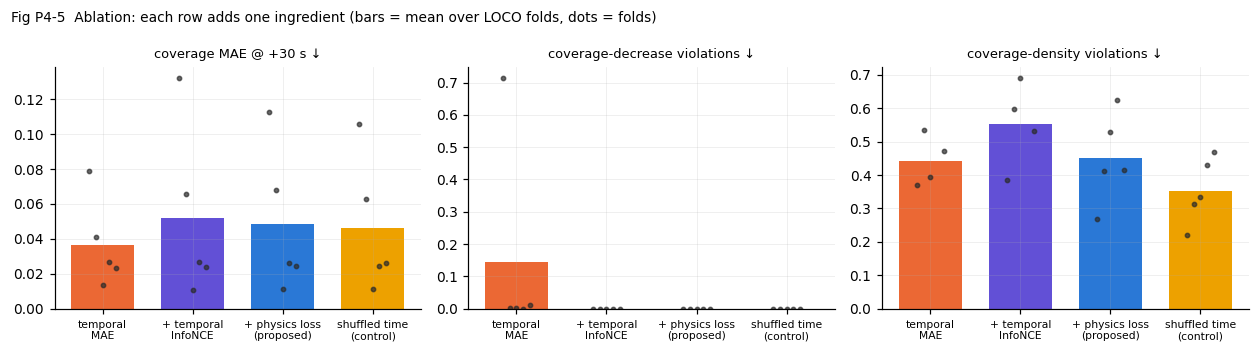

MAE         viol_mono         viol_cons        
           mean     std      mean     std      mean     std
model                                                      
B3       0.0366  0.0255    0.1455  0.3175    0.4433  0.0746
B4       0.0518  0.0492    0.0000  0.0000    0.5515  0.1278
B4+phys  0.0485  0.0417    0.0000  0.0000    0.4499  0.1349
B5+phys  0.0460  0.0385    0.0000  0.0000    0.3528  0.0976

In [12]:
# ---- 11. Fig P4-5: ablation (does each ingredient help?) + physics violations -------------------------------------------------
abl = [m for m in ['B3', 'B4', 'B4+phys', 'B5+phys'] if m in MODELS]
abl_lab = {'B3': 'temporal\nMAE', 'B4': '+ temporal\nInfoNCE', 'B4+phys': '+ physics loss\n(proposed)', 'B5+phys': 'shuffled time\n(control)'}
if abl:
    fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.2))
    for ax, (col, title) in zip(axes, [('MAE', f'{PRIMARY[0]} MAE @ +{PRIMARY[1]:.0f} s ↓'), ('viol_mono', 'coverage-decrease violations ↓'),
                                       ('viol_cons', 'coverage-density violations ↓')]):
        for j, m in enumerate(abl):
            d = prim[prim.model == m][col]
            ax.bar(j, d.mean(), color=MCOL[m], width=0.7)
            ax.plot(np.full(len(d), j) + np.linspace(-0.15, 0.15, len(d)), d, 'o', ms=2.8, color='#2b2b2b', alpha=0.7)
        ax.set_xticks(range(len(abl))); ax.set_xticklabels([abl_lab[m] for m in abl], fontsize=7); ax.set_title(title, fontsize=8.5)
    fig.suptitle('Fig P4-5  Ablation: each row adds one ingredient (bars = mean over LOCO folds, dots = folds)', fontsize=9, x=0.01, ha='left')
    fig.tight_layout(); fig.savefig(os.path.join(FIG, 'figP4_5_ablation_physics.png'), bbox_inches='tight'); plt.show()
    ABL = prim[prim.model.isin(abl)].groupby('model')[['MAE', 'viol_mono', 'viol_cons']].agg(['mean', 'std']).reindex(abl)
    display(ABL.round(4)); ABL.to_csv(os.path.join(OUT_DIR, 'ablation_table.csv'))

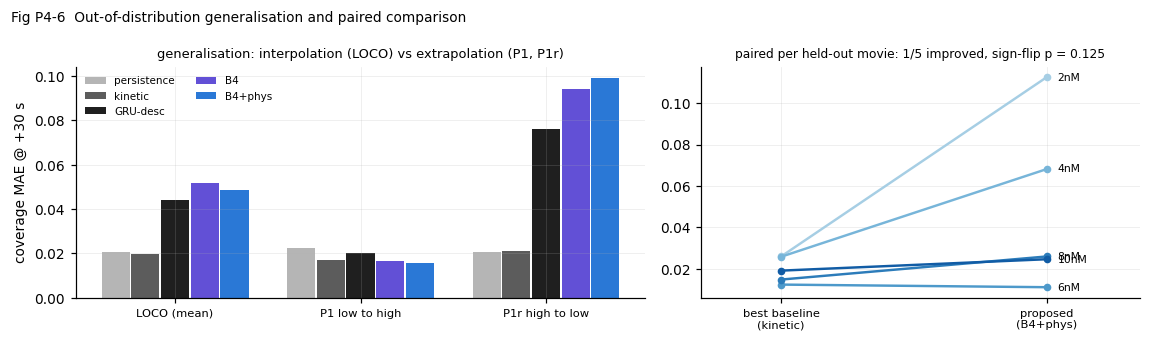

In [13]:
# ---- 12. Fig P4-6: generalisation across split types | Fig P4-7: paired per-fold comparison --------------------------------
gen_models = [m for m in ['persistence', 'kinetic', 'GRU-desc', 'B4', PROPOSED] if m in MODELS]
gp = MET[(MET.target == PRIMARY[0]) & (MET.horizon == PRIMARY[1]) & MET.model.isin(gen_models)].copy()
gp['protocol'] = np.where(gp.split.str.startswith('LOCO'), 'LOCO (mean)', gp.split)
G = gp.groupby(['protocol', 'model']).MAE.mean().unstack('model').reindex(columns=gen_models)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.1), gridspec_kw={'width_ratios': [1.3, 1]})
w = 0.8 / max(1, len(gen_models))
for j, m in enumerate(gen_models):
    axes[0].bar(np.arange(len(G)) + (j - (len(gen_models) - 1) / 2) * w, G[m], width=w * 0.95, color=MCOL[m], label=m)
axes[0].set_xticks(range(len(G))); axes[0].set_xticklabels([p.replace('_', ' ') for p in G.index], fontsize=7.5)
axes[0].set_ylabel(f'{PRIMARY[0]} MAE @ +{PRIMARY[1]:.0f} s'); axes[0].legend(fontsize=6.8, ncol=2)
axes[0].set_title('generalisation: interpolation (LOCO) vs extrapolation (P1, P1r)', fontsize=8.5)
if len(STATS):
    best_base = STATS[STATS.comparator.isin(['persistence', 'linear', 'kinetic', 'MLP-desc', 'GRU-desc'])].sort_values('mean_MAE_comparator').comparator.iloc[0]
    cols = [c for c in CONCS if c in tab.columns]
    for c in cols:
        axes[1].plot([0, 1], [tab.loc[best_base, c], tab.loc[PROPOSED, c]], '-o', color=CCOL.get(c, 'k'), ms=4)
        axes[1].text(1.04, tab.loc[PROPOSED, c], c, fontsize=7, va='center')
    axes[1].set_xticks([0, 1]); axes[1].set_xticklabels([f'best baseline\n({best_base})', f'proposed\n({PROPOSED})'], fontsize=7.5)
    rr_ = STATS.set_index('comparator').loc[best_base]
    axes[1].set_title(f'paired per held-out movie: {int(rr_.folds_won)}/{int(rr_.n_folds)} improved, sign-flip p = {rr_.p_signflip:.3f}', fontsize=8)
    axes[1].set_xlim(-0.3, 1.35)
fig.suptitle('Fig P4-6  Out-of-distribution generalisation and paired comparison', fontsize=9, x=0.01, ha='left')
fig.tight_layout(); fig.savefig(os.path.join(FIG, 'figP4_6_generalisation_paired.png'), bbox_inches='tight'); plt.show()

Observed kinetics after removing streak-flagged start-up frames (vs Portion 2):


,t50_s,t90_s,left_censored,t50_s_portion2,t90_s_portion2,left_censored_portion2
conc,,,,,,
2nM,NaN,NaN,False,NaN,NaN,False
4nM,267.8,386.2,False,267.8,386.2,False
6nM,13.5,86.5,False,13.5,86.5,False
8nM,29.9,131.8,True,0.0,131.8,True
10nM,75.2,103.0,False,75.2,103.0,False


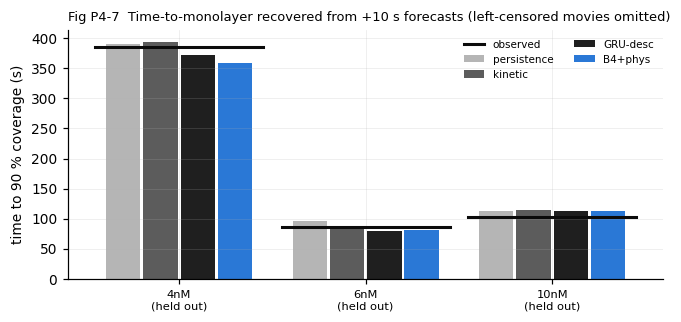

,conc,model,t90_observed,t90_forecast,left_censored,abs_err_s
0,2nM,persistence,NaN,NaN,False,NaN
1,2nM,kinetic,NaN,NaN,False,NaN
2,2nM,GRU-desc,NaN,NaN,False,NaN
3,2nM,B4+phys,NaN,NaN,False,NaN
4,4nM,persistence,386.2,390.1,False,3.8
5,4nM,kinetic,386.2,394.3,False,8.1
6,4nM,GRU-desc,386.2,371.5,False,14.7
7,4nM,B4+phys,386.2,359.2,False,27.1
8,6nM,persistence,86.5,96.5,False,10.0
9,6nM,kinetic,86.5,86.2,False,0.3


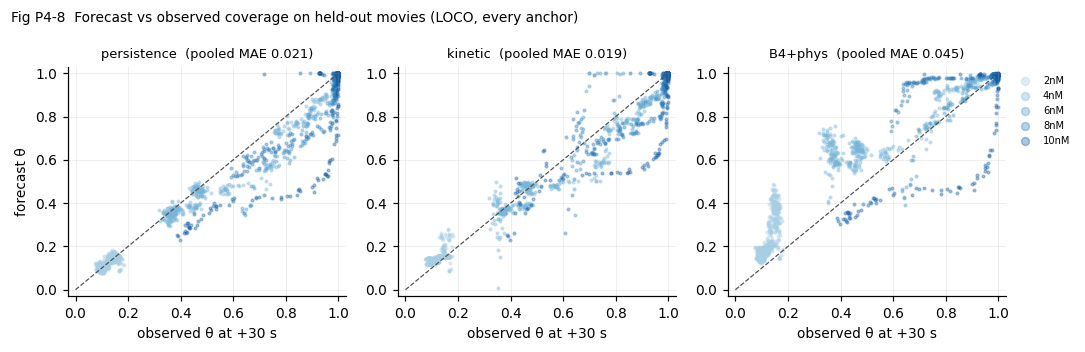

In [14]:
# ---- 13. Fig P4-7: time-to-90 % coverage predicted from the forecasts | Fig P4-8: predicted vs observed ------------------------------------------------------------
def first_sustained(t, y, thr=0.9, n_after=3, tol=0.02):
    for i in range(len(y)):
        if y[i] >= thr and np.all(y[i:i + n_after + 1] >= thr - tol):
            return float(t[i])
    return np.nan
# observed kinetics recomputed from the CLEANED measurements (streak-flagged start-up frames removed)
kin_rows = []
for c in CONCS:
    rr = np.where((A.conc.values == c) & MY[:, 0])[0]
    tt, yy = T_ABS[rr], pd.Series(Y[rr, 0]).rolling(5, center=True, min_periods=1).median().values
    kin_rows.append(dict(conc=c, t_first_valid_s=float(tt[0]), coverage_first=float(yy[0]), left_censored=bool(yy[0] >= 0.5),
                         t50_s=first_sustained(tt, yy, 0.5), t90_s=first_sustained(tt, yy, 0.9)))
kin = pd.DataFrame(kin_rows).set_index('conc'); kin.to_csv(os.path.join(OUT_DIR, 'kinetics_clean.csv'))
p2k = pd.read_csv(os.path.join(P2_DIR, 'kinetics_per_concentration.csv')).set_index('conc')
cmp_ = kin[['t50_s', 't90_s', 'left_censored']].join(p2k[['t50_s', 't90_s', 'left_censored']], rsuffix='_portion2')
print('Observed kinetics after removing streak-flagged start-up frames (vs Portion 2):'); display(cmp_.round(1))
h10 = 0
t90 = []
for s in loco:
    R = RES[s]; c = splits[s]['test'][0]; te_rows = R['te_rows']; o = np.argsort(T_ABS[te_rows])
    obs = kin.loc[c, 't90_s'] if c in kin.index else np.nan; cens = bool(kin.loc[c, 'left_censored']) if c in kin.index else True
    for m in [x for x in ['persistence', 'kinetic', 'GRU-desc', PROPOSED] if x in MODELS]:
        tt = T_ABS[te_rows][o] + HORIZONS[h10]; pp = R[m].mean(0)[o, h10, 0]
        t90.append(dict(conc=c, model=m, t90_observed=obs, t90_forecast=first_sustained(tt, pp), left_censored=cens))
T90 = pd.DataFrame(t90); T90['abs_err_s'] = (T90.t90_forecast - T90.t90_observed).abs()
T90.to_csv(os.path.join(OUT_DIR, 't90_forecast.csv'), index=False)
fig, ax = plt.subplots(figsize=(6.2, 3.0))
valid = T90[np.isfinite(T90.t90_observed) & ~T90.left_censored]
cl = sorted(valid.conc.unique(), key=conc_order); mm = [m for m in ['persistence', 'kinetic', 'GRU-desc', PROPOSED] if m in MODELS]
w = 0.8 / (len(mm) + 1)
w = 0.8 / len(mm)
for i, c in enumerate(cl):
    for j, m in enumerate(mm):
        v = valid[(valid.conc == c) & (valid.model == m)].t90_forecast
        ax.bar(i - 0.4 + w * (j + 0.5), 0 if v.isna().all() else v.iloc[0], width=w * 0.92, color=MCOL[m], label=m if i == 0 else None)
        if v.isna().all():
            ax.text(i - 0.4 + w * (j + 0.5), 5, 'n.r.', ha='center', fontsize=6.5, rotation=90)
    ob = valid[valid.conc == c].t90_observed.iloc[0]
    ax.plot([i - 0.45, i + 0.45], [ob, ob], color='#0b0b0b', lw=2.0, label='observed' if i == 0 else None)
ax.set_xticks(range(len(cl))); ax.set_xticklabels([f'{c}\n(held out)' for c in cl], fontsize=7.5); ax.set_ylabel('time to 90 % coverage (s)')
ax.legend(fontsize=6.8, ncol=2); ax.set_title('Fig P4-7  Time-to-monolayer recovered from +10 s forecasts (left-censored movies omitted)', fontsize=8.5, loc='left')
fig.tight_layout(); fig.savefig(os.path.join(FIG, 'figP4_7_t90_forecast.png'), bbox_inches='tight'); plt.show()
display(T90.round(1))

# Fig P4-8: predicted vs observed coverage at the primary horizon, all LOCO held-out anchors
hp = HORIZONS.index(PRIMARY[1]) if PRIMARY[1] in HORIZONS else 1
sc_models = [m for m in ['persistence', 'kinetic', PROPOSED] if m in MODELS]
fig, axes = plt.subplots(1, len(sc_models), figsize=(3.3 * len(sc_models), 3.2), squeeze=False)
for ax, m in zip(axes[0], sc_models):
    allm = []
    for s in loco:
        R = RES[s]; te_rows = R['te_rows']; c = splits[s]['test'][0]
        ok = MF[te_rows, hp, 0]; y = YF[te_rows, hp, 0][ok]; p = R[m].mean(0)[ok, hp, 0]
        ax.scatter(y, p, s=3, alpha=0.35, color=CCOL.get(c, 'k'), label=c); allm.append(np.abs(p - y))
    ax.plot([0, 1], [0, 1], color='#52514e', lw=0.8, ls='--')
    mae_all = float(np.mean(np.concatenate(allm))) if allm else np.nan
    ax.set_title(f'{m}  (pooled MAE {mae_all:.3f})', fontsize=8.5); ax.set_xlabel(f'observed θ at +{PRIMARY[1]:.0f} s'); ax.set_xlim(-0.03, 1.03); ax.set_ylim(-0.03, 1.03)
axes[0, 0].set_ylabel('forecast θ'); axes[0, -1].legend(fontsize=6.5, markerscale=3, loc='upper left', bbox_to_anchor=(1.0, 1.0))
fig.suptitle('Fig P4-8  Forecast vs observed coverage on held-out movies (LOCO, every anchor)', fontsize=9, x=0.01, ha='left')
fig.tight_layout(); fig.savefig(os.path.join(FIG, 'figP4_8_pred_vs_obs.png'), bbox_inches='tight'); plt.show()

In [15]:
# ---- 14. Hypothesis checks & summary --------------------------------------------------------------------------------------------
def mean_prim(m):
    return float(tab.loc[m, 'mean']) if m in tab.index else np.nan
def won(m_a, m_b):
    cols = [c for c in CONCS if c in tab.columns]
    return int((tab.loc[m_a, cols] < tab.loc[m_b, cols]).sum()) if (m_a in tab.index and m_b in tab.index) else 0
nF = len([c for c in CONCS if c in tab.columns])
checks = [('All splits evaluated, no encoder saw its test movie', 'PASS', f'{len(SPLIT_LIST)} splits; leakage asserted per split x variant')]
if PROPOSED in MODELS:
    checks += [
        ('H4: proposed beats persistence (≥ n-1 folds)', 'SUPPORTED' if won(PROPOSED, 'persistence') >= nF - 1 else 'NOT SUPPORTED',
         f'{won(PROPOSED, "persistence")}/{nF} folds; {mean_prim(PROPOSED):.4f} vs {mean_prim("persistence"):.4f}'),
        ('H5: proposed beats the kinetic fit', 'SUPPORTED' if mean_prim(PROPOSED) < mean_prim('kinetic') else 'NOT SUPPORTED',
         f'{won(PROPOSED, "kinetic")}/{nF} folds; {mean_prim(PROPOSED):.4f} vs {mean_prim("kinetic"):.4f}'),
        ('H6: images add information beyond descriptors (vs GRU-desc)', 'SUPPORTED' if mean_prim(PROPOSED) < mean_prim('GRU-desc') else 'NOT SUPPORTED',
         f'{won(PROPOSED, "GRU-desc")}/{nF} folds; {mean_prim(PROPOSED):.4f} vs {mean_prim("GRU-desc"):.4f}')]
    if 'B4' in MODELS:
        vb4 = prim[prim.model == 'B4'].viol_mono.mean(); vp = prim[prim.model == PROPOSED].viol_mono.mean()
        ok = (vp <= vb4) and (mean_prim(PROPOSED) <= 1.05 * mean_prim('B4'))
        checks.append(('H7: physics loss cuts violations without costing >5 % accuracy', 'SUPPORTED' if ok else 'NOT SUPPORTED',
                       f'violations {vp:.3f} vs {vb4:.3f}; MAE {mean_prim(PROPOSED):.4f} vs {mean_prim("B4"):.4f}'))
    if 'B5+phys' in MODELS:
        checks.append(('H8: true time order matters (proposed < shuffled control)', 'SUPPORTED' if mean_prim(PROPOSED) < mean_prim('B5+phys') else 'NOT SUPPORTED',
                       f'{won(PROPOSED, "B5+phys")}/{nF} folds; {mean_prim(PROPOSED):.4f} vs {mean_prim("B5+phys"):.4f}'))
CH = pd.DataFrame(checks, columns=['check', 'status', 'detail']); display(CH)
CH.to_csv(os.path.join(OUT_DIR, 'checks_portion4.csv'), index=False)
json.dump(dict(created=datetime.now().isoformat(timespec='seconds'), device=str(DEVICE), torch=torch.__version__, models=MODELS,
               splits=SPLIT_LIST, portion3_quick=QUICK_P3,
               config={k: v for k, v in globals().items() if k.isupper() and isinstance(v, (int, float, str, bool, tuple))}),
          open(os.path.join(OUT_DIR, 'run_config_portion4.json'), 'w'), indent=1, default=str)
if QUICK_P3:
    print('\nPortion 3 ran in QUICK mode, so these numbers only prove the pipeline works - rerun Portion 3 on an A100 first.')
print('Outputs:', sorted(os.listdir(OUT_DIR)))

,check,status,detail
0,"All splits evaluated, no encoder saw its test ...",PASS,7 splits; leakage asserted per split x variant
1,H4: proposed beats persistence (≥ n-1 folds),NOT SUPPORTED,2/5 folds; 0.0485 vs 0.0207
2,H5: proposed beats the kinetic fit,NOT SUPPORTED,1/5 folds; 0.0485 vs 0.0196
3,H6: images add information beyond descriptors ...,NOT SUPPORTED,2/5 folds; 0.0485 vs 0.0439
4,H7: physics loss cuts violations without costi...,SUPPORTED,violations 0.000 vs 0.000; MAE 0.0485 vs 0.0518
5,H8: true time order matters (proposed < shuffl...,NOT SUPPORTED,2/5 folds; 0.0485 vs 0.0460


Outputs: ['ablation_table.csv', 'checks_portion4.csv', 'figures', 'kinetics_clean.csv', 'metrics_all.csv', 'paired_stats_primary.csv', 'predictions', 'run_config_portion4.json', 't90_forecast.csv']


## What you have now (`portion4_outputs/`)
| File | Use |
|---|---|
| `metrics_all.csv` | every split × model × target × horizon: MAE, RMSE, R², Spearman, seed SD, physics-violation rates |
| `paired_stats_primary.csv` | proposed vs each comparator over LOCO folds: mean improvement, 95 % CI, Cohen's d_z, folds won, exact sign-flip p, BH q |
| `ablation_table.csv`, `t90_forecast.csv` | ablation rows and time-to-monolayer recovered from forecasts |
| `predictions/<split>.npz` | raw forecasts (seeds × anchors × horizons × targets) for Portion 5 figures and uncertainty |
| `figures/figP4_*.png` | task diagram, held-out forecast curves, error-vs-horizon, skill heatmap, ablation, generalisation + paired plot, t90, forecast-vs-observed |
| `checks_portion4.csv` | H4–H8 reported as SUPPORTED / NOT SUPPORTED (negative results are results) |

**Statistics note:** with 5 held-out movies the smallest possible two-sided sign-flip p-value is 0.0625 (6 movies: 0.031).
Report the per-fold improvements, the CI and the effect size alongside p — and the external dataset in Portion 5 is what makes the claim strong.